# TP5 — Un projet de bout en bout (corrigé)
**CNFSDP — Introduction au Machine Learning** · L3 S5 · 2026-2027 · Rois Céti DIMBAMBA · chapitre 5 · 45 min en salle

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rdimbamba/ml-cnfsdp/blob/main/notebooks/corriges/TP5_corrige.ipynb)

On fabrique d'abord un **faux fichier « enfants » au format DHS** (Stata et SPSS, codes et étiquettes), puis on le traite exactement comme le vrai fichier de l'EDS Congo que vous utiliserez pour le projet.
Les données sont fictives : aucune ne provient d'une enquête réelle. **Les vraies données DHS ne doivent jamais être déposées sur GitHub ni partagées.**

In [1]:
# Lecture des fichiers SPSS : pyreadstat (déjà présent dans l'environnement ml-cnfsdp ; à installer sur Colab)
try:
    import pyreadstat
except ImportError:
    %pip install -q pyreadstat
    import pyreadstat

In [2]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, recall_score, precision_score
VERT, OR, GRIS = "#126B2A", "#B8860B", "#8A8A8A"   # couleurs du cours

Fabrication du fichier fictif (à exécuter sans le modifier) :

In [3]:
ETIQUETTES = {
    "v024": {1: "région A", 2: "région B", 3: "région C", 4: "région D"},
    "v025": {1: "urbain", 2: "rural"},
    "v106": {0: "aucune", 1: "primaire", 2: "secondaire", 3: "supérieur"},
    "v190": {1: "le plus pauvre", 2: "pauvre", 3: "moyen", 4: "riche", 5: "le plus riche"},
    "b4": {1: "masculin", 2: "féminin"},
    "m15": {11: "domicile", 21: "hôpital public", 31: "clinique privée", 96: "autre"},
    "v467d": {1: "gros problème", 2: "pas un gros problème"},
    "m14": {98: "ne sait pas"},
}

def simuler_enfants(n=3000, graine=0):
    """Enfants de 12 à 23 mois, fictifs, avec les noms et codes de variables du fichier KR des DHS."""
    rng = np.random.default_rng(graine)
    urbain = rng.random(n) < 0.45
    richesse = rng.standard_normal(n) + 1.1 * urbain
    v190 = np.clip(np.digitize(richesse, [-0.9, -0.2, 0.5, 1.2]) + 1, 1, 5)
    v106 = np.clip(np.round(0.9 + 0.7 * richesse + 0.5 * rng.standard_normal(n)), 0, 3).astype(int)
    v024 = rng.choice([1, 2, 3, 4], n, p=[0.35, 0.25, 0.25, 0.15])
    v467d = np.where(rng.random(n) < np.where(urbain, 0.15, 0.55), 1, 2)
    m14 = np.clip(rng.poisson(np.where(urbain, 5.5, 3.5) + 0.6 * (v106 - 1)), 0, 15)
    m15 = np.where(rng.random(n) < 1 / (1 + np.exp(-(0.3 + 1.2 * urbain + 0.5 * v106 - 0.8))),
                   rng.choice([21, 31], n, p=[0.8, 0.2]), rng.choice([11, 96], n, p=[0.9, 0.1]))
    bord = 1 + rng.poisson(np.where(urbain, 1.5, 2.6))
    b4 = rng.choice([1, 2], n)
    hw1 = rng.integers(12, 24, n)
    t = (-0.9 + 0.45 * v106 + 0.35 * (v190 - 3) + 0.35 * urbain - 0.7 * (v467d == 1)
         + 0.12 * np.minimum(m14, 8) + 0.6 * np.isin(m15, [21, 31]) - 0.12 * (bord - 1)
         + np.select([v024 == 4, v024 == 3], [-0.6, 0.3], 0.0))
    p = 1 / (1 + np.exp(-t))
    nb_doses = np.where(rng.random(n) < p, 8, rng.binomial(7, 0.6, n))
    m14 = np.where(rng.random(n) < 0.06, 98, m14)                    # 6 % de « ne sait pas »
    return pd.DataFrame({"caseid": np.arange(1, n + 1), "v024": v024, "v025": np.where(urbain, 1, 2),
                         "v106": v106, "v190": v190, "b4": b4, "bord": bord, "hw1": hw1, "m14": m14,
                         "m15": m15, "v467d": v467d, "nb_doses": nb_doses,
                         "vacc_complet": (nb_doses == 8).astype(int)})

os.makedirs("donnees", exist_ok=True)
enfants = simuler_enfants()
enfants.to_stata("donnees/ZZKR_FICTIF.DTA", write_index=False, version=118,
                 value_labels={k: v for k, v in ETIQUETTES.items() if k != "m14"},
                 variable_labels={"v106": "niveau d'instruction de la mère", "v025": "milieu de résidence",
                                  "m14": "nombre de visites prénatales", "vacc_complet": "vaccination complète"})
pyreadstat.write_sav(enfants, "donnees/ZZKR_FICTIF.SAV", variable_value_labels=ETIQUETTES)
print(os.listdir("donnees"))

['ZZKR_FICTIF.DTA', 'ZZKR_FICTIF.SAV']


## Question 1 — Lire un fichier DHS
Lire les étiquettes avec `pd.io.stata.StataReader`, puis seulement les colonnes utiles avec `pd.read_stata(..., columns=..., convert_categoricals=False)`. Recoder le code 98 de `m14` (« ne sait pas ») en valeur manquante. Relire le fichier SPSS avec `pd.read_spss` et vérifier qu'il a la même taille. Donner le taux de vaccination complète par milieu (codes 1 = urbain, 2 = rural).

In [4]:
fichier = "donnees/ZZKR_FICTIF.DTA"
with pd.io.stata.StataReader(fichier) as lecteur:
    etiquettes = lecteur.value_labels()
    libelles = lecteur.variable_labels()
print(libelles["v106"], etiquettes["v106"])
print(etiquettes["m15"])

colonnes = ["v024", "v025", "v106", "v190", "b4", "bord", "hw1", "m14", "m15", "v467d", "nb_doses", "vacc_complet"]
df = pd.read_stata(fichier, columns=colonnes, convert_categoricals=False)
df["m14"] = df["m14"].replace(98, np.nan)
print(df.shape, "| manquants m14 :", df["m14"].isna().sum())
spss = pd.read_spss("donnees/ZZKR_FICTIF.SAV", usecols=colonnes)
print("SPSS :", spss.shape)
print(df.groupby("v025")["vacc_complet"].mean().round(3).rename(index=etiquettes["v025"]))

niveau d'instruction de la mère {np.int32(0): 'aucune', np.int32(1): 'primaire', np.int32(2): 'secondaire', np.int32(3): 'supérieur'}
{np.int32(11): 'domicile', np.int32(21): 'hôpital public', np.int32(31): 'clinique privée', np.int32(96): 'autre'}
(3000, 12) | manquants m14 : 197
SPSS : (3000, 12)
v025
urbain    0.777
rural     0.405
Name: vacc_complet, dtype: float64


## Question 2 — Pipeline et comparaison de modèles
Variables qualitatives : `v024, v025, b4, m15, v467d` ; numériques : `v106, v190, bord, hw1, m14`. Découper (70 % / 30 %, stratifié, `random_state=0`), construire la préparation (indicatrices ; imputation par la médiane puis standardisation), comparer logistique, forêt et gradient boosting par AUC en validation croisée. Évaluer ensuite le meilleur **une seule fois** sur le test : AUC et exactitude avec son intervalle de confiance à 95 %.

In [5]:
qual = ["v024", "v025", "b4", "m15", "v467d"]; quant = ["v106", "v190", "bord", "hw1", "m14"]
df[quant] = df[quant].astype(float)
X, y = df[qual + quant], df["vacc_complet"]
Xa, Xt, ya, yt = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
prep = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), qual),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), quant))
modeles = {"logistique": LogisticRegression(max_iter=1000),
           "forêt": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=0),
           "boosting": GradientBoostingClassifier(random_state=0)}
for nom, m in modeles.items():
    auc = cross_val_score(make_pipeline(prep, m), Xa, ya, cv=5, scoring="roc_auc")
    print(f"{nom:10s} AUC = {auc.mean():.3f} (écart type {auc.std():.3f})")

f = make_pipeline(prep, LogisticRegression(max_iter=1000)).fit(Xa, ya)
p = f.score(Xt, yt); m = len(yt)
print(f"test : AUC = {roc_auc_score(yt, f.predict_proba(Xt)[:, 1]):.3f} | exactitude = {p:.3f} "
      f"± {1.96 * np.sqrt(p * (1 - p) / m):.3f}")

logistique AUC = 0.805 (écart type 0.014)


forêt      AUC = 0.796 (écart type 0.016)


boosting   AUC = 0.787 (écart type 0.018)
test : AUC = 0.824 | exactitude = 0.743 ± 0.029


## Question 3 — Deux fuites d'information
1. Ajouter `nb_doses` aux variables numériques et refaire la validation croisée de la logistique. Pourquoi ce score est-il trompeur ?
2. Sur 200 individus, 2 000 variables de bruit et une cible au hasard : choisir les 20 variables les plus liées à $y$ (`SelectKBest`) **sur toutes les données** puis faire une validation croisée ; recommencer avec la sélection **dans** le pipeline.

In [6]:
prep2 = make_column_transformer(
    (OneHotEncoder(handle_unknown="ignore"), qual),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), quant + ["nb_doses"]))
X2 = df.loc[Xa.index, qual + quant + ["nb_doses"]]
auc = cross_val_score(make_pipeline(prep2, LogisticRegression(max_iter=1000)), X2, ya, cv=5, scoring="roc_auc")
print("avec nb_doses : AUC =", auc.mean().round(3))

rng = np.random.default_rng(0)
B = rng.standard_normal((200, 2000)); yb = rng.integers(0, 2, 200)
Bs = SelectKBest(f_classif, k=20).fit_transform(B, yb)                       # sélection sur tout : fuite
print("sélection avant la validation croisée :", cross_val_score(LogisticRegression(), Bs, yb, cv=5).mean().round(3))
honnete = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())   # sélection dans chaque bloc
print("sélection dans le pipeline :", cross_val_score(honnete, B, yb, cv=5).mean().round(3))

avec nb_doses : AUC = 1.0
sélection avant la validation croisée : 0.755
sélection dans le pipeline : 0.555


## Question 4 — Interpréter le modèle
Calculer l'importance par permutation (AUC, 20 répétitions) sur le test et la tracer. Calculer la dépendance partielle de `v106` (instruction de la mère) : probabilité moyenne prédite quand on impose 0, 1, 2 puis 3 à tous les enfants.

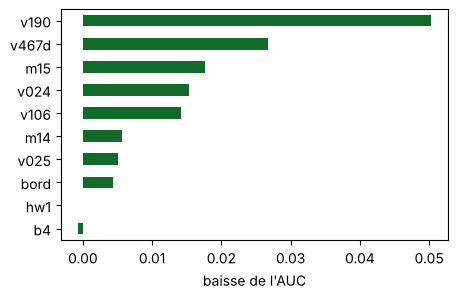

{np.float64(0.0): np.float64(0.489), np.float64(1.0): np.float64(0.559), np.float64(2.0): np.float64(0.628), np.float64(3.0): np.float64(0.692)}


In [7]:
r = permutation_importance(f, Xt, yt, scoring="roc_auc", n_repeats=20, random_state=0)
imp = pd.Series(r.importances_mean, index=X.columns).sort_values()
imp.plot.barh(color=VERT, figsize=(5, 3)); plt.xlabel("baisse de l'AUC"); plt.show()

pdp = partial_dependence(f, Xa, ["v106"], kind="average")
print(dict(zip(pdp["grid_values"][0], pdp["average"][0].round(3))))

## Question 5 — Confidentialité
1. Quelle part des enfants est seule dans sa case quand on croise région, milieu, sexe, âge en mois, rang de naissance et instruction de la mère ?
2. Le nombre d'enfants non vaccinés de la région D doit être publié avec le mécanisme de Laplace. Tirer 5 publications pour $\varepsilon=1$ puis pour $\varepsilon=0{,}1$ (`rng.laplace(0, 1/eps)`).

In [8]:
cles = ["v024", "v025", "b4", "hw1", "bord", "v106"]
taille = df.groupby(cles)["v025"].transform("size")
print(f"enfants uniques : {(taille == 1).mean():.1%} | dans une case d'au plus 3 : {(taille <= 3).mean():.1%}")

N = int(((df["v024"] == 4) & (df["vacc_complet"] == 0)).sum())
rng = np.random.default_rng(1)
print("vrai nombre :", N)
for eps in [1, 0.1]:
    print(f"epsilon = {eps} :", np.round(N + rng.laplace(0, 1 / eps, 5)).astype(int))

enfants uniques : 37.1% | dans une case d'au plus 3 : 86.1%
vrai nombre : 234
epsilon = 1 : [234 236 233 236 234]
epsilon = 0.1 : [232 245 232 235 205]


## Question 6 — Audit d'équité
Le modèle « signale » un enfant si sa probabilité prédite de vaccination complète est inférieure à 0,5. Par milieu, calculer la part d'enfants signalés, le rappel et la précision (positif = non vacciné). Chercher ensuite, pour chaque milieu, le seuil qui donne un rappel d'environ 0,75, et recalculer l'audit.

*Remarque : en pratique, on choisit ces seuils sur l'apprentissage (par validation croisée), pas sur le test.*

In [9]:
p_non = 1 - f.predict_proba(Xt)[:, 1]          # probabilité prédite d'être non vacciné
non_vacc = (yt == 0).values
def audit(seuils):
    for g, milieu in [(1, "urbain"), (2, "rural")]:
        m = (Xt["v025"] == g).values
        s = p_non[m] > seuils[g]
        print(f"{milieu:7s} seuil {seuils[g]:.2f} | signalés {s.mean():.0%} | rappel {recall_score(non_vacc[m], s):.2f}"
              f" | précision {precision_score(non_vacc[m], s):.2f}")
audit({1: 0.5, 2: 0.5})

seuils = {}
for g in [1, 2]:
    m = (Xt["v025"] == g).values
    seuils[g] = np.quantile(p_non[m][non_vacc[m]], 0.25)    # 75 % des non vaccinés au-dessus du seuil
print()
audit(seuils)

urbain  seuil 0.50 | signalés 8% | rappel 0.27 | précision 0.68
rural   seuil 0.50 | signalés 66% | rappel 0.77 | précision 0.71

urbain  seuil 0.16 | signalés 57% | rappel 0.75 | précision 0.26
rural   seuil 0.53 | signalés 62% | rappel 0.75 | précision 0.73


**Conclusion attendue.** La logistique fait aussi bien que les méthodes d'ensemble sur ces données. Une variable qui contient la réponse ou une sélection faite avant le découpage donne des scores faussement excellents. Le modèle repère mal les enfants urbains non vaccinés : avec un seuil par milieu, on égalise les rappels, au prix de plus de signalements en ville. Ces choix se justifient dans le rapport.